In [4]:
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import PIL
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix


In [5]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("birdy654/cifake-real-and-ai-generated-synthetic-images")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\nguye\.cache\kagglehub\datasets\birdy654\cifake-real-and-ai-generated-synthetic-images\versions\3


In [6]:
# Load data from the directory returned by kagglehub.dataset_download.
from pathlib import Path

data_root = Path(path)
train_dir = data_root / "train"
test_dir = data_root / "test"

batch_size = 32
image_size = (32, 32)
seed = 1337

train_images = tf.keras.utils.image_dataset_from_directory(
    str(train_dir),
    image_size=image_size,
    batch_size=batch_size,
    validation_split=0.2,
    subset="training",
    seed=seed,
    label_mode="binary",
    shuffle=True,
)

validation_images = tf.keras.utils.image_dataset_from_directory(
    str(train_dir),
    image_size=image_size,
    batch_size=batch_size,
    validation_split=0.2,
    subset="validation",
    seed=seed,
    label_mode="binary",
    shuffle=True,
)

test_images = tf.keras.utils.image_dataset_from_directory(
    str(test_dir),
    image_size=image_size,
    batch_size=batch_size,
    label_mode="binary",
    shuffle=False,
)

class_names = train_images.class_names
print("Dataset root:", data_root)
print("Classes:", class_names)

train_images = train_images.prefetch(tf.data.AUTOTUNE)
validation_images = validation_images.prefetch(tf.data.AUTOTUNE)
test_images = test_images.prefetch(tf.data.AUTOTUNE)


Found 100000 files belonging to 2 classes.
Using 80000 files for training.
Found 100000 files belonging to 2 classes.
Using 20000 files for validation.
Found 20000 files belonging to 2 classes.
Dataset root: C:\Users\nguye\.cache\kagglehub\datasets\birdy654\cifake-real-and-ai-generated-synthetic-images\versions\3
Classes: ['FAKE', 'REAL']


In [3]:
# Verify that each split contains both classes.
def count_dataset_labels(dataset):
    labels = np.concatenate([batch_labels.numpy().ravel() for _, batch_labels in dataset])
    return np.bincount(labels.astype(int), minlength=2)

print("Training label counts [FAKE, REAL]:", count_dataset_labels(train_images))
print("Validation label counts [FAKE, REAL]:", count_dataset_labels(validation_images))
print("Test label counts [FAKE, REAL]:", count_dataset_labels(test_images))


Training label counts [FAKE, REAL]: [40090 39910]
Validation label counts [FAKE, REAL]: [ 9910 10090]
Test label counts [FAKE, REAL]: [10000 10000]


In [ ]:
# Preprocess images for MobileNetV2.
# MobileNetV2 expects 224x224 RGB images and pixel values scaled to [-1, 1].
mobilenet_image_size = (224, 224)

mobilenet_preprocess = tf.keras.applications.mobilenet_v2.preprocess_input 

def preprocess_for_mobilenet(images, labels):
    images = tf.image.resize(images, mobilenet_image_size)
    images = mobilenet_preprocess(images)
    return images, labels

train_mobilenet = train_images.map(
    preprocess_for_mobilenet,
    num_parallel_calls=tf.data.AUTOTUNE,
)
validation_mobilenet = validation_images.map(
    preprocess_for_mobilenet,
    num_parallel_calls=tf.data.AUTOTUNE,
)
test_mobilenet = test_images.map(
    preprocess_for_mobilenet,
    num_parallel_calls=tf.data.AUTOTUNE,
)

train_mobilenet = train_mobilenet.prefetch(tf.data.AUTOTUNE)
validation_mobilenet = validation_mobilenet.prefetch(tf.data.AUTOTUNE)
test_mobilenet = test_mobilenet.prefetch(tf.data.AUTOTUNE)


In [5]:
# Verify the MobileNetV2 input format.
for images, labels in train_mobilenet.take(1):
    print("MobileNetV2 image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Preprocessed pixel range:", float(tf.reduce_min(images)), "to", float(tf.reduce_max(images)))


MobileNetV2 image batch shape: (32, 224, 224, 3)
Label batch shape: (32, 1)
Preprocessed pixel range: -1.0 to 1.0


In [6]:
# Build the binary CIFAKE transfer-learning model.
base_model = keras.applications.MobileNetV2(
    input_shape=(*mobilenet_image_size, 3),
    include_top=False,
    weights="imagenet",
)
base_model.trainable = False

inputs = keras.Input(shape=(*mobilenet_image_size, 3))
features = base_model(inputs, training=False)
features = keras.layers.GlobalAveragePooling2D()(features)
features = keras.layers.Dropout(0.2)(features)
outputs = keras.layers.Dense(1, activation="sigmoid")(features)
model = keras.Model(inputs, outputs)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc"),
    ],
)
model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [7]:
# Confirm that the model produces one binary probability per image.
sample_images, _ = next(iter(train_mobilenet.take(1)))
sample_predictions = model(sample_images, training=False)
print("Input shape:", sample_images.shape)
print("Output shape:", sample_predictions.shape)
print("Output range:", float(tf.reduce_min(sample_predictions)), "to", float(tf.reduce_max(sample_predictions)))


Input shape: (32, 224, 224, 3)
Output shape: (32, 1)
Output range: 0.0658605769276619 to 0.7512049674987793


In [ ]:
# Train the new binary classification head while MobileNetV2 remains frozen.
initial_epochs = 3
training_callbacks = [
    keras.callbacks.EarlyStopping( 
        monitor="val_auc",
        mode="max",
        patience=1,
        restore_best_weights=True,
    ),
    keras.callbacks.ReduceLROnPlateau( # Reduce learning rate when a metric has stopped improving.
        monitor="val_loss",
        factor=0.2,
        patience=1,
        min_lr=1e-6,
    ),
]
history_head = model.fit(
    train_mobilenet,
    validation_data=validation_mobilenet,
    epochs=initial_epochs,
    callbacks=training_callbacks,
)


Epoch 1/3
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 1994s 795ms/step - accuracy: 0.8278 - auc: 0.9103 - loss: 0.3795 - precision: 0.8289 - recall: 0.8251 - val_accuracy: 0.8644 - val_auc: 0.9403 - val_loss: 0.3140 - val_precision: 0.8763 - val_recall: 0.8513 - learning_rate: 0.0010
Epoch 2/3
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 1966s 786ms/step - accuracy: 0.8516 - auc: 0.9285 - loss: 0.3412 - precision: 0.8516 - recall: 0.8509 - val_accuracy: 0.8680 - val_auc: 0.9428 - val_loss: 0.3072 - val_precision: 0.8787 - val_recall: 0.8565 - learning_rate: 0.0010
Epoch 3/3
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 1865s 746ms/step - accuracy: 0.8527 - auc: 0.9295 - loss: 0.3394 - precision: 0.8525 - recall: 0.8522 - val_accuracy: 0.8701 - val_auc: 0.9437 - val_loss: 0.3041 - val_precision: 0.8672 - val_recall: 0.8768 - learning_rate: 0.0010


In [11]:
# Fine-tune the later MobileNetV2 layers with a smaller learning rate.
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

# Batch-normalization statistics remain frozen during fine-tuning.
for layer in base_model.layers:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc"),
    ],
)

fine_tune_epochs = 3
history_fine_tune = model.fit(
    train_mobilenet,
    validation_data=validation_mobilenet,
    initial_epoch=len(history_head.epoch),
    epochs=len(history_head.epoch) + fine_tune_epochs,
    callbacks=training_callbacks,
)


Epoch 4/6
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 1887s 751ms/step - accuracy: 0.9068 - auc: 0.9681 - loss: 0.2285 - precision: 0.9051 - recall: 0.9084 - val_accuracy: 0.9333 - val_auc: 0.9830 - val_loss: 0.1686 - val_precision: 0.9456 - val_recall: 0.9206 - learning_rate: 1.0000e-05
Epoch 5/6
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 2866s 1s/step - accuracy: 0.9400 - auc: 0.9856 - loss: 0.1521 - precision: 0.9390 - recall: 0.9407 - val_accuracy: 0.9431 - val_auc: 0.9876 - val_loss: 0.1454 - val_precision: 0.9581 - val_recall: 0.9277 - learning_rate: 1.0000e-05
Epoch 6/6
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 2424s 969ms/step - accuracy: 0.9535 - auc: 0.9909 - loss: 0.1198 - precision: 0.9526 - recall: 0.9543 - val_accuracy: 0.9444 - val_auc: 0.9892 - val_loss: 0.1469 - val_precision: 0.9207 - val_recall: 0.9736 - learning_rate: 1.0000e-05


In [13]:
# Evaluate on the untouched test set.
test_metrics = model.evaluate(test_mobilenet, return_dict=True)
print("Test metrics:")
for metric_name, metric_value in test_metrics.items():
    print(f"{metric_name}: {metric_value:.4f}")

probabilities = model.predict(test_mobilenet).ravel()
true_labels = np.concatenate(
    [labels.numpy().ravel() for _, labels in test_mobilenet]
).astype(int)
predicted_labels = (probabilities >= 0.5).astype(int)

print("\nClassification report:")
print(
    classification_report(
        true_labels,
        predicted_labels,
        target_names=class_names,
        digits=4,
    )
)

confusion = confusion_matrix(true_labels, predicted_labels)
print("Confusion matrix:")
print(confusion)


625/625 ━━━━━━━━━━━━━━━━━━━━ 487s 777ms/step - accuracy: 0.9442 - auc: 0.9891 - loss: 0.1476 - precision: 0.9195 - recall: 0.9738
Test metrics:
accuracy: 0.9442
auc: 0.9891
loss: 0.1476
precision: 0.9195
recall: 0.9738
625/625 ━━━━━━━━━━━━━━━━━━━━ 552s 877ms/step

Classification report:
              precision    recall  f1-score   support

        FAKE     0.9722    0.9147    0.9426     10000
        REAL     0.9195    0.9738    0.9459     10000

    accuracy                         0.9443     20000
   macro avg     0.9458    0.9443    0.9442     20000
weighted avg     0.9458    0.9443    0.9442     20000

Confusion matrix:
[[9147  853]
 [ 262 9738]]


      Stage Final validation accuracy Final validation AUC Final validation loss
Frozen base                    0.8701               0.9437                0.3041
 Fine-tuned                    0.9444               0.9892                0.1469


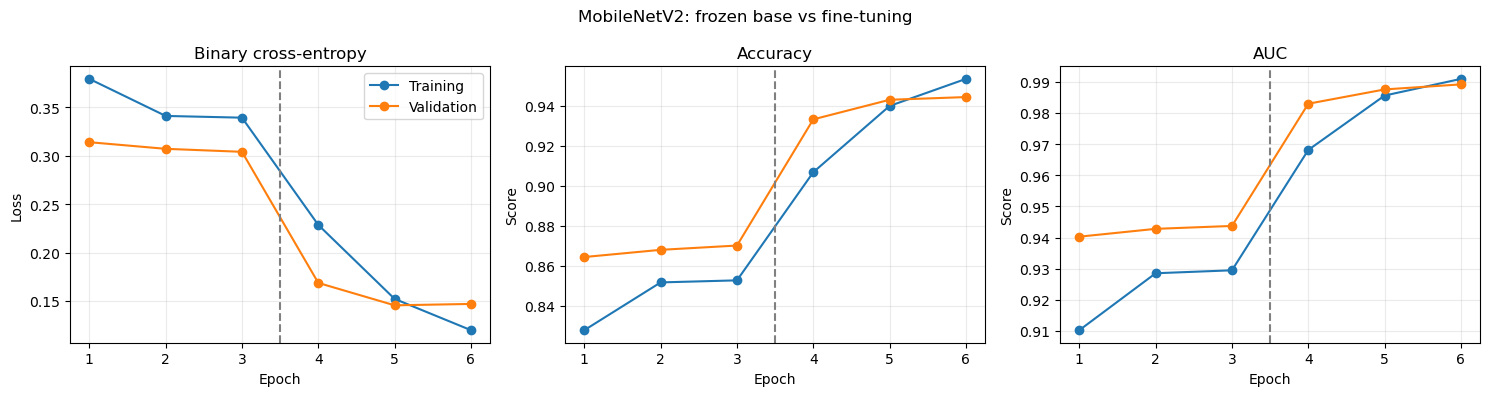

In [12]:
# Compare frozen-base training with fine-tuning using their validation histories.
head_epochs = len(history_head.history["loss"])
fine_epochs = len(history_fine_tune.history["loss"])
epochs = np.arange(1, head_epochs + fine_epochs + 1)

comparison = pd.DataFrame(
    {
        "Stage": ["Frozen base", "Fine-tuned"],
        "Final validation accuracy": [
            history_head.history["val_accuracy"][-1],
            history_fine_tune.history["val_accuracy"][-1],
        ],
        "Final validation AUC": [
            history_head.history["val_auc"][-1],
            history_fine_tune.history["val_auc"][-1],
        ],
        "Final validation loss": [
            history_head.history["val_loss"][-1],
            history_fine_tune.history["val_loss"][-1],
        ],
    }
)
print(comparison.to_string(index=False, formatters={
    "Final validation accuracy": "{:.4f}".format,
    "Final validation AUC": "{:.4f}".format,
    "Final validation loss": "{:.4f}".format,
}))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for axis, metric, title in zip(
    axes,
    ["loss", "accuracy", "auc"],
    ["Binary cross-entropy", "Accuracy", "AUC"],
):
    train_values = history_head.history[metric] + history_fine_tune.history[metric]
    validation_values = history_head.history[f"val_{metric}"] + history_fine_tune.history[f"val_{metric}"]
    axis.plot(epochs, train_values, marker="o", label="Training")
    axis.plot(epochs, validation_values, marker="o", label="Validation")
    axis.axvline(head_epochs + 0.5, color="gray", linestyle="--")
    axis.set_title(title)
    axis.set_xlabel("Epoch")
    axis.set_xticks(epochs)
    axis.grid(alpha=0.25)
axes[0].set_ylabel("Loss")
axes[1].set_ylabel("Score")
axes[2].set_ylabel("Score")
axes[0].legend()
fig.suptitle("MobileNetV2: frozen base vs fine-tuning")
fig.tight_layout()
plt.show()
